Name : Nagawade Chirag Somnath
PRN : 202502110009

# Autoencoder vs Variational Autoencoder (VAE) on MNIST
**Aim:** Build an Autoencoder (AE) and a Variational Autoencoder (VAE) for image reconstruction and generation, and compare the quality of reconstructed and generated images.

**Dataset:** MNIST (28x28 grayscale handwritten digits)  
**Framework:** PyTorch  

**Outline**
1. Setup & data loading
2. Autoencoder (AE) – model & training
3. Variational Autoencoder (VAE) – model & training
4. Training curves
5. Reconstruction comparison (visual + MSE / PSNR / SSIM)
6. Image generation comparison (visual + classifier-based quality proxy)
7. Latent space analysis & interpolation
8. Conclusion

## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.decomposition import PCA

try:
    from skimage.metrics import structural_similarity as ssim_fn
except ImportError:
    !pip install -q scikit-image
    from skimage.metrics import structural_similarity as ssim_fn

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 42.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.06MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.46MB/s]


Train images: 60000 | Test images: 10000
Batch shape: torch.Size([128, 1, 28, 28])


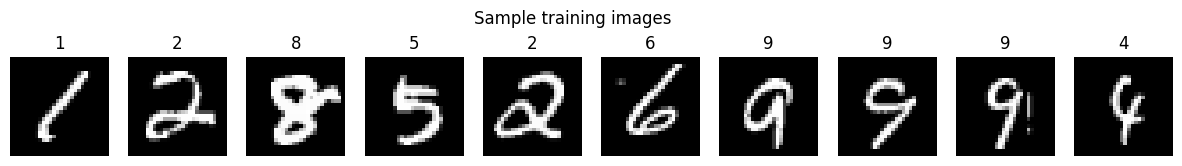

In [2]:
BATCH_SIZE = 128
LATENT_DIM = 16
EPOCHS = 20
LR = 1e-3

transform = transforms.ToTensor()          # pixel values in [0, 1]
train_ds = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print("Train images:", len(train_ds), "| Test images:", len(test_ds))
x, y = next(iter(train_loader))
print("Batch shape:", x.shape)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(x[i, 0], cmap="gray"); ax.axis("off"); ax.set_title(int(y[i]))
plt.suptitle("Sample training images"); plt.show()

## 2. Autoencoder (AE)
A convolutional autoencoder compresses each image into a **deterministic** latent vector `z` (16-D) and reconstructs it.  
Loss: Binary Cross-Entropy (reconstruction only).

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_dim, variational=False):
        super().__init__()
        self.variational = variational
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),   # 14x14
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),  # 7x7
            nn.Flatten(),
        )
        if variational:
            self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
            self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        else:
            self.fc = nn.Linear(64 * 7 * 7, latent_dim)

    def forward(self, x):
        h = self.conv(x)
        if self.variational:
            return self.fc_mu(h), self.fc_logvar(h)
        return self.fc(h)


class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU())
        self.deconv = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 14x14
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 28x28
        )

    def forward(self, z):
        return self.deconv(self.fc(z))


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(latent_dim, variational=False)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


ae = Autoencoder().to(device)
print(ae)
print("AE parameters:", sum(p.numel() for p in ae.parameters()))

Autoencoder(
  (encoder): Encoder(
    (conv): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Flatten(start_dim=1, end_dim=-1)
    )
    (fc): Linear(in_features=3136, out_features=16, bias=True)
  )
  (decoder): Decoder(
    (fc): Sequential(
      (0): Linear(in_features=16, out_features=3136, bias=True)
      (1): ReLU()
    )
    (deconv): Sequential(
      (0): Unflatten(dim=1, unflattened_size=(64, 7, 7))
      (1): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
      (2): ReLU()
      (3): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
      (4): Sigmoid()
    )
  )
)
AE parameters: 141073


In [4]:
def train_ae(model, epochs=EPOCHS):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train": [], "test": []}
    for ep in range(1, epochs + 1):
        model.train(); total = 0
        for x, _ in train_loader:
            x = x.to(device)
            recon, _ = model(x)
            loss = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * x.size(0)
        train_loss = total / len(train_ds)

        model.eval(); total = 0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(device)
                recon, _ = model(x)
                total += F.binary_cross_entropy(recon, x, reduction="sum").item()
        test_loss = total / len(test_ds)
        history["train"].append(train_loss); history["test"].append(test_loss)
        print(f"[AE] Epoch {ep:02d}/{epochs} | train loss {train_loss:.3f} | test loss {test_loss:.3f}")
    return history

ae_hist = train_ae(ae)

[AE] Epoch 01/20 | train loss 145.591 | test loss 89.319
[AE] Epoch 02/20 | train loss 85.093 | test loss 80.215
[AE] Epoch 03/20 | train loss 79.067 | test loss 76.537
[AE] Epoch 04/20 | train loss 76.024 | test loss 74.280
[AE] Epoch 05/20 | train loss 74.127 | test loss 72.850
[AE] Epoch 06/20 | train loss 72.762 | test loss 72.074
[AE] Epoch 07/20 | train loss 71.771 | test loss 71.126
[AE] Epoch 08/20 | train loss 70.969 | test loss 70.397
[AE] Epoch 09/20 | train loss 70.337 | test loss 69.882
[AE] Epoch 10/20 | train loss 69.782 | test loss 69.507
[AE] Epoch 11/20 | train loss 69.309 | test loss 68.937
[AE] Epoch 12/20 | train loss 68.905 | test loss 68.777
[AE] Epoch 13/20 | train loss 68.555 | test loss 68.372
[AE] Epoch 14/20 | train loss 68.239 | test loss 68.069
[AE] Epoch 15/20 | train loss 67.980 | test loss 67.824
[AE] Epoch 16/20 | train loss 67.723 | test loss 67.912
[AE] Epoch 17/20 | train loss 67.502 | test loss 67.415
[AE] Epoch 18/20 | train loss 67.286 | test los

## 3. Variational Autoencoder (VAE)
The VAE encoder outputs a **distribution** (`mu`, `log σ²`) instead of a single point. We sample `z = mu + σ·ε` (reparameterisation trick) and regularise the latent space towards `N(0, I)`.

**Loss = Reconstruction (BCE) + KL divergence**, where  
`KL = -0.5 · Σ (1 + log σ² − μ² − σ²)`

In [5]:
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(latent_dim, variational=True)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x, reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return bce, kld


vae = VAE().to(device)
print("VAE parameters:", sum(p.numel() for p in vae.parameters()))

VAE parameters: 191265


In [6]:
def train_vae(model, epochs=EPOCHS):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train": [], "test": [], "train_bce": [], "train_kl": []}
    for ep in range(1, epochs + 1):
        model.train(); tot = bce_t = kl_t = 0
        for x, _ in train_loader:
            x = x.to(device)
            recon, mu, logvar = model(x)
            bce, kld = vae_loss(recon, x, mu, logvar)
            loss = (bce + kld) / x.size(0)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += (bce + kld).item(); bce_t += bce.item(); kl_t += kld.item()
        n = len(train_ds)

        model.eval(); test_tot = 0
        with torch.no_grad():
            for x, _ in test_loader:
                x = x.to(device)
                recon, mu, logvar = model(x)
                b, k = vae_loss(recon, x, mu, logvar)
                test_tot += (b + k).item()
        history["train"].append(tot / n); history["test"].append(test_tot / len(test_ds))
        history["train_bce"].append(bce_t / n); history["train_kl"].append(kl_t / n)
        print(f"[VAE] Epoch {ep:02d}/{epochs} | train {tot/n:.3f} (BCE {bce_t/n:.3f}, KL {kl_t/n:.3f}) | test {test_tot/len(test_ds):.3f}")
    return history

vae_hist = train_vae(vae)

[VAE] Epoch 01/20 | train 169.592 (BCE 151.691, KL 17.901) | test 121.500
[VAE] Epoch 02/20 | train 117.010 (BCE 93.744, KL 23.266) | test 112.332
[VAE] Epoch 03/20 | train 111.381 (BCE 87.709, KL 23.672) | test 109.030
[VAE] Epoch 04/20 | train 108.851 (BCE 84.946, KL 23.904) | test 107.133
[VAE] Epoch 05/20 | train 107.400 (BCE 83.353, KL 24.047) | test 106.137
[VAE] Epoch 06/20 | train 106.319 (BCE 82.164, KL 24.155) | test 105.298
[VAE] Epoch 07/20 | train 105.557 (BCE 81.302, KL 24.255) | test 104.605
[VAE] Epoch 08/20 | train 104.839 (BCE 80.527, KL 24.312) | test 103.939
[VAE] Epoch 09/20 | train 104.331 (BCE 79.954, KL 24.377) | test 103.667
[VAE] Epoch 10/20 | train 103.888 (BCE 79.470, KL 24.418) | test 103.220
[VAE] Epoch 11/20 | train 103.457 (BCE 79.021, KL 24.437) | test 102.842
[VAE] Epoch 12/20 | train 103.055 (BCE 78.613, KL 24.442) | test 102.576
[VAE] Epoch 13/20 | train 102.735 (BCE 78.283, KL 24.452) | test 102.204
[VAE] Epoch 14/20 | train 102.430 (BCE 77.948, KL 

## 4. Training Curves

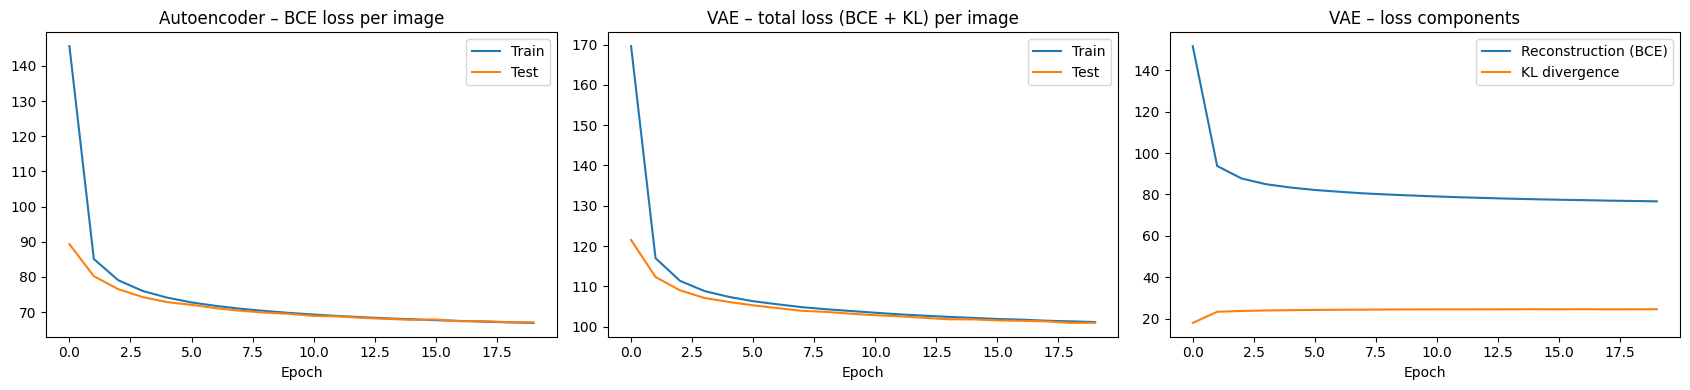

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(ae_hist["train"], label="Train"); axes[0].plot(ae_hist["test"], label="Test")
axes[0].set_title("Autoencoder – BCE loss per image"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(vae_hist["train"], label="Train"); axes[1].plot(vae_hist["test"], label="Test")
axes[1].set_title("VAE – total loss (BCE + KL) per image"); axes[1].set_xlabel("Epoch"); axes[1].legend()

axes[2].plot(vae_hist["train_bce"], label="Reconstruction (BCE)"); axes[2].plot(vae_hist["train_kl"], label="KL divergence")
axes[2].set_title("VAE – loss components"); axes[2].set_xlabel("Epoch"); axes[2].legend()
plt.tight_layout(); plt.show()

## 5. Reconstruction Comparison
We reconstruct unseen **test** images with both models and compare them visually and with three metrics:
- **MSE** (lower is better)
- **PSNR** in dB (higher is better)
- **SSIM** (closer to 1 is better)

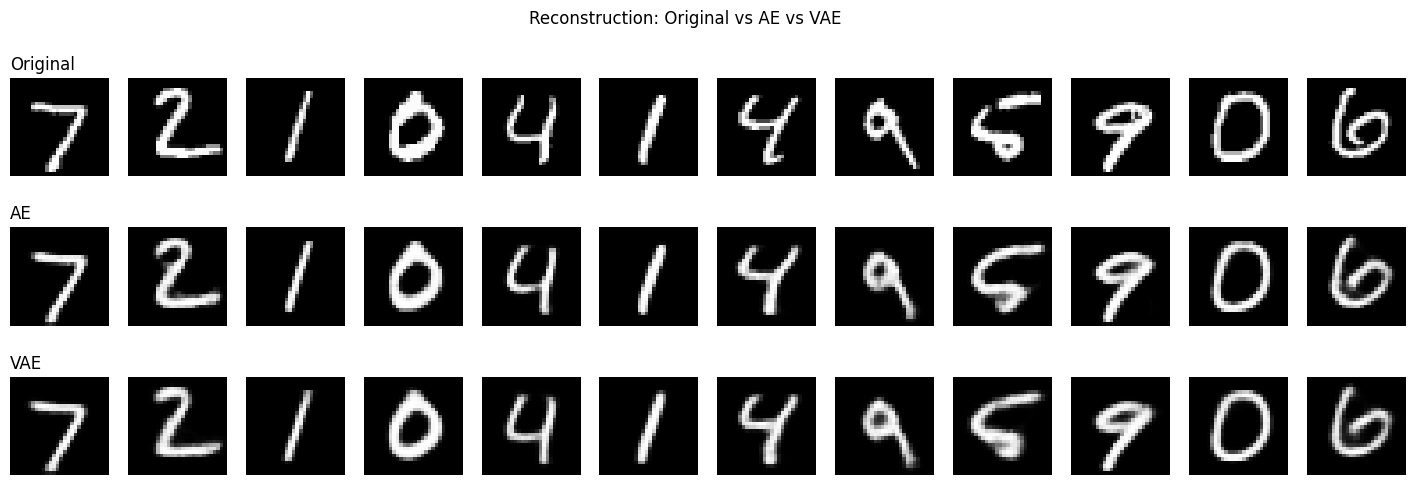

In [8]:
ae.eval(); vae.eval()
x_test, y_test = next(iter(test_loader))
x_test = x_test.to(device)

with torch.no_grad():
    ae_recon, _ = ae(x_test)
    mu, logvar = vae.encoder(x_test)
    vae_recon = vae.decoder(mu)          # use the mean for deterministic reconstruction

n = 12
fig, axes = plt.subplots(3, n, figsize=(18, 5.5))
for i in range(n):
    axes[0, i].imshow(x_test[i, 0].cpu(), cmap="gray")
    axes[1, i].imshow(ae_recon[i, 0].cpu(), cmap="gray")
    axes[2, i].imshow(vae_recon[i, 0].cpu(), cmap="gray")
    for r in range(3): axes[r, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("AE", loc="left"); axes[2, 0].set_title("VAE", loc="left")
plt.suptitle("Reconstruction: Original vs AE vs VAE"); plt.show()

In [9]:
@torch.no_grad()
def evaluate_reconstruction(model, is_vae):
    mses, psnrs, ssims = [], [], []
    for x, _ in test_loader:
        x = x.to(device)
        if is_vae:
            mu, _ = model.encoder(x); recon = model.decoder(mu)
        else:
            recon, _ = model(x)
        mse = ((recon - x) ** 2).mean(dim=(1, 2, 3))
        mses.extend(mse.cpu().tolist())
        psnrs.extend((10 * torch.log10(1.0 / mse.clamp_min(1e-10))).cpu().tolist())
        xs, rs = x.cpu().numpy()[:, 0], recon.cpu().numpy()[:, 0]
        ssims.extend([ssim_fn(a, b, data_range=1.0) for a, b in zip(xs, rs)])
    return np.mean(mses), np.mean(psnrs), np.mean(ssims)

ae_m, vae_m = evaluate_reconstruction(ae, False), evaluate_reconstruction(vae, True)
recon_df = pd.DataFrame({"MSE (↓)": [ae_m[0], vae_m[0]],
                         "PSNR dB (↑)": [ae_m[1], vae_m[1]],
                         "SSIM (↑)": [ae_m[2], vae_m[2]]}, index=["Autoencoder", "VAE"]).round(4)
recon_df

,MSE (↓),PSNR dB (↑),SSIM (↑)
Autoencoder,0.0080,21.9520,0.9165
VAE,0.0087,21.3839,0.9017


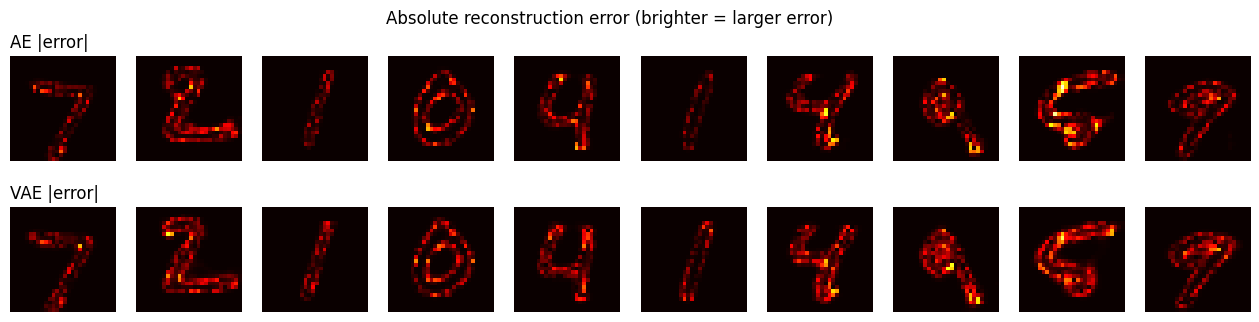

In [10]:
# Per-image error maps for a few digits
err_ae  = (x_test - ae_recon).abs().cpu()
err_vae = (x_test - vae_recon).abs().cpu()
fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for i in range(10):
    axes[0, i].imshow(err_ae[i, 0], cmap="hot", vmin=0, vmax=1);  axes[0, i].axis("off")
    axes[1, i].imshow(err_vae[i, 0], cmap="hot", vmin=0, vmax=1); axes[1, i].axis("off")
axes[0, 0].set_title("AE |error|", loc="left"); axes[1, 0].set_title("VAE |error|", loc="left")
plt.suptitle("Absolute reconstruction error (brighter = larger error)"); plt.show()

## 6. Image Generation Comparison
- **VAE:** sample `z ~ N(0, I)` and decode — this is exactly what the VAE was trained for.
- **AE (naive):** sample `z ~ N(0, I)` and decode — an AE has no constraint on its latent distribution, so this is expected to work poorly.
- **AE (fitted Gaussian):** a fairer baseline — fit a Gaussian to the AE's actual latent codes of the training data and sample from it.

In [ ]:
@torch.no_grad()
def get_latents(model, is_vae, loader):
    zs, ys = [], []
    for x, y in loader:
        x = x.to(device)
        z = model.encoder(x)[0] if is_vae else model.encoder(x)
        zs.append(z.cpu()); ys.append(y)
    return torch.cat(zs), torch.cat(ys)

z_ae_train, _ = get_latents(ae, False, DataLoader(train_ds, batch_size=512))
mean_ae = z_ae_train.mean(0)
cov_ae = torch.cov(z_ae_train.T) + 1e-4 * torch.eye(LATENT_DIM)
mvn = torch.distributions.MultivariateNormal(mean_ae, covariance_matrix=cov_ae)

N_GEN = 64
torch.manual_seed(0)
z_prior = torch.randn(N_GEN, LATENT_DIM).to(device)
z_fit   = mvn.sample((N_GEN,)).to(device)

with torch.no_grad():
    gen_vae       = vae.decoder(z_prior).cpu()
    gen_ae_naive  = ae.decoder(z_prior).cpu()
    gen_ae_fitted = ae.decoder(z_fit).cpu()

def show_grid(imgs, title, ax, nrow=8):
    grid = imgs.view(-1, 28, 28)[:nrow * nrow].numpy()
    rows = [np.concatenate(grid[r*nrow:(r+1)*nrow], axis=1) for r in range(nrow)]
    ax.imshow(np.concatenate(rows, axis=0), cmap="gray"); ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
show_grid(gen_ae_naive,  "AE – z ~ N(0, I)  (naive)", axes[0])
show_grid(gen_ae_fitted, "AE – z ~ Gaussian fitted to latents", axes[1])
show_grid(gen_vae,       "VAE – z ~ N(0, I)", axes[2])
plt.tight_layout(); plt.show()

### Quantitative proxy for generation quality
Generated images have no ground truth, so we train a small CNN classifier on real MNIST and use it as a judge:
- **Mean confidence** – how confidently the classifier recognises a digit (higher ⇒ images look like clear digits).
- **Class entropy** – diversity of generated classes (max = log 10 ≈ 2.303 ⇒ all digits equally produced).

In [12]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

clf = Classifier().to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(3):
    clf.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(x), y); opt.zero_grad(); loss.backward(); opt.step()
clf.eval(); correct = 0
with torch.no_grad():
    for x, y in test_loader:
        correct += (clf(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f"Classifier test accuracy: {correct / len(test_ds):.4f}")

Classifier test accuracy: 0.9869


In [ ]:
@torch.no_grad()
def generation_stats(decoder, sampler, n=5000):
    z = sampler(n).to(device)
    imgs = decoder(z)
    probs = F.softmax(clf(imgs), dim=1)
    conf = probs.max(1).values.mean().item()
    counts = torch.bincount(probs.argmax(1), minlength=10).float()
    p = counts / counts.sum()
    entropy = -(p[p > 0] * p[p > 0].log()).sum().item()
    return conf, entropy, counts.int().tolist()

stats = {
  "AE (naive N(0,I))":       generation_stats(ae.decoder,  lambda n: torch.randn(n, LATENT_DIM)),
  "AE (fitted Gaussian)":    generation_stats(ae.decoder,  lambda n: mvn.sample((n,))),
  "VAE (N(0,I))":            generation_stats(vae.decoder, lambda n: torch.randn(n, LATENT_DIM)),
}
gen_df = pd.DataFrame({k: {"Mean confidence (↑)": v[0], "Class entropy (↑, max 2.303)": v[1]} for k, v in stats.items()}).T.round(4)
display(gen_df)

fig, ax = plt.subplots(figsize=(10, 3.5))
w = 0.27
for i, (k, v) in enumerate(stats.items()):
    ax.bar(np.arange(10) + (i - 1) * w, v[2], width=w, label=k)
ax.set_xticks(range(10)); ax.set_xlabel("Predicted digit class"); ax.set_ylabel("Count (of 5000)")
ax.set_title("Class distribution of generated images"); ax.legend(); plt.show()

## 7. Latent Space Analysis & Interpolation

In [ ]:
z_ae, y_lat = get_latents(ae,  False, test_loader)
z_vae, _    = get_latents(vae, True,  test_loader)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, z, name in zip(axes, [z_ae, z_vae], ["Autoencoder", "VAE (μ)"]):
    z2 = PCA(n_components=2).fit_transform(z.numpy())
    sc = ax.scatter(z2[:, 0], z2[:, 1], c=y_lat, cmap="tab10", s=3, alpha=0.7)
    ax.set_title(f"{name} latent space (PCA to 2-D)")
plt.colorbar(sc, ax=axes, ticks=range(10), label="Digit")
plt.show()

print("AE  latent: mean |z| = %.2f, std = %.2f" % (z_ae.abs().mean(), z_ae.std()))
print("VAE latent: mean |μ| = %.2f, std = %.2f  (close to N(0,1) because of the KL term)" % (z_vae.abs().mean(), z_vae.std()))

In [ ]:
# Latent interpolation between two test digits (A -> B)
@torch.no_grad()
def interpolate(idx_a, idx_b, steps=10):
    xa, xb = test_ds[idx_a][0].unsqueeze(0).to(device), test_ds[idx_b][0].unsqueeze(0).to(device)
    za, zb = ae.encoder(xa), ae.encoder(xb)
    ma, mb = vae.encoder(xa)[0], vae.encoder(xb)[0]
    ts = torch.linspace(0, 1, steps).view(-1, 1).to(device)
    return ae.decoder((1 - ts) * za + ts * zb).cpu(), vae.decoder((1 - ts) * ma + ts * mb).cpu()

pairs = [(0, 1), (2, 3), (4, 7)]
fig, axes = plt.subplots(len(pairs) * 2, 10, figsize=(14, 2.0 * len(pairs) * 2))
for p, (a, b) in enumerate(pairs):
    ia, iv = interpolate(a, b)
    for j in range(10):
        axes[2*p, j].imshow(ia[j, 0], cmap="gray");   axes[2*p, j].axis("off")
        axes[2*p+1, j].imshow(iv[j, 0], cmap="gray"); axes[2*p+1, j].axis("off")
    axes[2*p, 0].set_title("AE interpolation", loc="left", fontsize=9)
    axes[2*p+1, 0].set_title("VAE interpolation", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# Bonus: VAE latent traversal – vary each latent dimension for the first 8 dims
@torch.no_grad()
def traverse(model, base_z, dims=8, steps=9, rng=3.0):
    rows = []
    for d in range(dims):
        z = base_z.repeat(steps, 1)
        z[:, d] = torch.linspace(-rng, rng, steps)
        rows.append(np.concatenate(model.decoder(z.to(device)).cpu()[:, 0].numpy(), axis=1))
    return np.concatenate(rows, axis=0)

plt.figure(figsize=(12, 9))
plt.imshow(traverse(vae, torch.zeros(1, LATENT_DIM)), cmap="gray")
plt.title("VAE latent traversal (each row varies one latent dimension from -3 to +3)"); plt.axis("off"); plt.show()

## 8. Summary Table

In [17]:
summary = recon_df.copy()
summary["Gen. confidence (↑)"] = [stats["AE (fitted Gaussian)"][0], stats["VAE (N(0,I))"][0]]
summary["Gen. class entropy (↑)"] = [stats["AE (fitted Gaussian)"][1], stats["VAE (N(0,I))"][1]]
print("(AE generation uses the fitted-Gaussian sampler – its best case.)")
summary.round(4)

(AE generation uses the fitted-Gaussian sampler – its best case.)


,MSE (↓),PSNR dB (↑),SSIM (↑),Gen. confidence (↑),Gen. class entropy (↑)
Autoencoder,0.0080,21.9520,0.9165,0.8202,2.253
VAE,0.0087,21.3839,0.9017,0.8089,2.258


## 9. Conclusion

**Reconstruction.** The Autoencoder optimises *only* reconstruction error, so it typically achieves lower MSE and higher PSNR/SSIM and produces sharper reconstructions. The VAE adds a KL regulariser that forces the latent code to be noisy and close to `N(0, I)`, creating an information bottleneck; its reconstructions are therefore usually slightly blurrier with somewhat worse reconstruction metrics.

**Generation.** The plain AE has no mechanism that makes its latent space smooth or matched to a known prior. Sampling from `N(0, I)` therefore usually yields distorted or non-digit images, and even a Gaussian fitted to its latents is only a partial fix. The VAE's latent space is regularised towards `N(0, I)`, so sampling from the prior gives mostly recognisable digits with good class diversity. The classifier-based confidence and entropy scores quantify this gap.

**Latent space and interpolation.** The VAE's latent space is compact and continuous, giving smooth interpolations between digits and meaningful latent traversals. The AE's latent space is irregular, with gaps between clusters and less meaningful interpolations.

**Trade-off.** *AE = better reconstruction / compression; VAE = a principled generative model* that trades a little reconstruction sharpness for reliable generation and a structured latent space. (Exact numbers vary slightly by run – refer to the tables and figures above.)

**Possible improvements:** β-VAE to tune the reconstruction/KL trade-off, a larger latent dimension, perceptual or adversarial losses to reduce VAE blurriness, and a Conditional VAE for class-controlled generation.